In [1]:
import sys; sys.path.append('../..')
from src.modelos.dados import ler_base, preparar, dividir
from src.modelos.variaveis import criar_variaveis
from src.modelos.treino import _para_modelo, metricas, metricas_por_grupo, calibracao_por_faixa, salvar
from src.modelos.xgb import GRADE, buscar_parametros, treinar_final

base = preparar(ler_base())
treino, teste = dividir(base)
treino = criar_variaveis(treino)
teste = criar_variaveis(teste, referencia=treino)

grade = buscar_parametros(treino)
print(grade.head(5))

from src.modelos.xgb import treinar_final_completo

melhor = grade.iloc[0]
params = {k: int(melhor[k]) for k in GRADE}
m = treinar_final_completo(treino, params, int(melhor['n_arvores']))

# 3. Teste 2016 (uma vez só)
p = m.predict_proba(_para_modelo(teste))[:, 1]
print('\nTeste:', metricas(teste['default'], p))
print(metricas_por_grupo(teste, p, 'pais'))
print(calibracao_por_faixa(teste['default'], p))

import sys; sys.path.insert(0, '../../src/dados')
from pathlib import Path
from carga_macro import _ler_euribor
from src.modelos.prever import montar_pacote, salvar_pacote

e12 = _ler_euribor(Path('../../data/raw/ECB_Euribor_Serie-Mensal-12-Meses.csv'),
                   'EURIBOR1YD_', 'euribor_12m')
pac = montar_pacote(m, treino, e12)
print(salvar_pacote(pac))

import json
from src.modelos.prever import prever
from tests.modelos.test_contrato_prever import validar_saida_prever

for _, linha in teste.sample(5, random_state=1).iterrows():
    saida = prever(linha.to_dict(), pac)
    validar_saida_prever(saida)
    print(json.dumps(saida, ensure_ascii=False, indent=1)[:600], '\n')

salvar(m, 'xgboost_v2', {'params': params, 'teste': metricas(teste['default'], p)})

   max_depth  min_child_weight  reg_lambda  n_arvores  contratos  \
0          3                 5          10        288       5943   
1          4                20           1        161       5943   
2          3                 5           1        214       5943   
3          3                20          10        161       5943   
4          3                20           1        213       5943   

   default_real  default_previsto     auc      ks   brier  
0        0.6655            0.6646  0.7216  0.3339  0.1901  
1        0.6655            0.6659  0.7215  0.3338  0.1901  
2        0.6655            0.6637  0.7214  0.3293  0.1901  
3        0.6655            0.6643  0.7213  0.3264  0.1901  
4        0.6655            0.6640  0.7207  0.3313  0.1902  



Teste: {'contratos': 7311, 'default_real': 0.6708, 'default_previsto': 0.5592, 'auc': 0.7255, 'ks': 0.3356, 'brier': 0.2004}
      contratos  default_real  default_previsto     auc      ks   brier
pais                                                                   
EE         3642        0.5472            0.4350  0.7099  0.3133  0.2272
ES         2226        0.8293            0.7050  0.6418  0.2183  0.1538
FI         1443        0.7380            0.6475  0.5681  0.1209  0.2047
                 contratos  prevista   real
faixa                                      
(0.0427, 0.269]        732     0.188  0.269
(0.269, 0.375]         731     0.325  0.476
(0.375, 0.468]         731     0.424  0.539
(0.468, 0.536]         731     0.504  0.674
(0.536, 0.592]         731     0.565  0.689
(0.592, 0.641]         731     0.618  0.751
(0.641, 0.69]          731     0.666  0.780
(0.69, 0.735]          731     0.712  0.807
(0.735, 0.791]         731     0.763  0.839
(0.791, 0.926]         731    

{
 "contrato_id": "5423075e-74a2-4f1e-ac86-a6b100d5cd80",
 "versao_modelo": "xgboost_v2",
 "juro_cobrado": 0.3093,
 "pd": 0.4806,
 "pd_ic95": null,
 "faixa": "C",
 "juro_justo": 0.198,
 "juro_justo_min": 0.178,
 "juro_justo_max": 0.218,
 "diferenca_pp": 11.1,
 "situacao_preco": "acima_do_justo",
 "motivos": [
  {
   "variavel": "tipo_verificacao",
   "rotulo": "verificação da renda",
   "efeito": "reduz_risco",
   "valor": "4",
   "peso": 0.167
  },
  {
   "variavel": "escolaridade",
   "rotulo": "escolaridade",
   "efeito": "reduz_risco",
   "valor": "5",
   "peso": 0.139
  },
  {
   "variave 

{
 "contrato_id": "a6bb4bef-10a1-435e-8681-a60a00f4312e",
 "versao_modelo": "xgboost_v2",
 "juro_cobrado": 0.6155,
 "pd": 0.4425,
 "pd_ic95": null,
 "faixa": "B",
 "juro_justo": 0.4973,
 "juro_justo_min": 0.4773,
 "juro_justo_max": 0.5173,
 "diferenca_pp": 11.8,
 "situacao_preco": "acima_do_justo",
 "motivos": [
  {
   "variavel": "prazo_meses",
   "rotulo": "prazo do empréstimo",
   "efeito": 

{
 "contrato_id": "5a13795d-7d10-4f11-b241-2a163ce93a13",
 "versao_modelo": "xgboost_v2",
 "juro_cobrado": 0.2694,
 "pd": 0.752,
 "pd_ic95": null,
 "faixa": "E",
 "juro_justo": 0.2428,
 "juro_justo_min": 0.2228,
 "juro_justo_max": 0.2628,
 "diferenca_pp": 2.7,
 "situacao_preco": "acima_do_justo",
 "motivos": [
  {
   "variavel": "prazo_meses",
   "rotulo": "prazo do empréstimo",
   "efeito": "aumenta_risco",
   "valor": 60.0,
   "peso": 0.231
  },
  {
   "variavel": "escolaridade",
   "rotulo": "escolaridade",
   "efeito": "aumenta_risco",
   "valor": "2",
   "peso": 0.152
  },
  {
   "variave 

{
 "contrato_id": "87819bb4-4adc-469c-b4eb-a6d300bc0ebb",
 "versao_modelo": "xgboost_v2",
 "juro_cobrado": 0.2278,
 "pd": 0.6596,
 "pd_ic95": null,
 "faixa": "D",
 "juro_justo": 0.1959,
 "juro_justo_min": 0.1759,
 "juro_justo_max": 0.2159,
 "diferenca_pp": 3.2,
 "situacao_preco": "acima_do_justo",
 "motivos": [
  {
   "variavel": "prazo_meses",
   "rotulo": "prazo do empréstimo",
   "efeito": "

{
 "contrato_id": "67df5dbe-a578-49f4-abdb-a5dd005c413e",
 "versao_modelo": "xgboost_v2",
 "juro_cobrado": 0.3585,
 "pd": 0.5291,
 "pd_ic95": null,
 "faixa": "C",
 "juro_justo": 0.3188,
 "juro_justo_min": 0.2988,
 "juro_justo_max": 0.3388,
 "diferenca_pp": 4.0,
 "situacao_preco": "acima_do_justo",
 "motivos": [
  {
   "variavel": "tipo_verificacao",
   "rotulo": "verificação da renda",
   "efeito": "aumenta_risco",
   "valor": "1",
   "peso": 0.159
  },
  {
   "variavel": "prazo_meses",
   "rotulo": "prazo do empréstimo",
   "efeito": "reduz_risco",
   "valor": 24.0,
   "peso": 0.136
  },
  {
 



WindowsPath('C:/Users/samue/OneDrive/Desktop/tcs/Auditor-Project/modelos_salvos/xgboost_v2.joblib')

                               contratos  default_real  default_previsto  \
nosso_modelo                      7311.0        0.6708            0.5592   
pd_bondora                        7311.0        0.6708            0.3360   
nosso_modelo_mesmos_contratos     7311.0        0.6708            0.5592   

                                  auc      ks   brier  
nosso_modelo                   0.7255  0.3356  0.2004  
pd_bondora                     0.6697  0.2490  0.3226  
nosso_modelo_mesmos_contratos  0.7255  0.3356  0.2004  


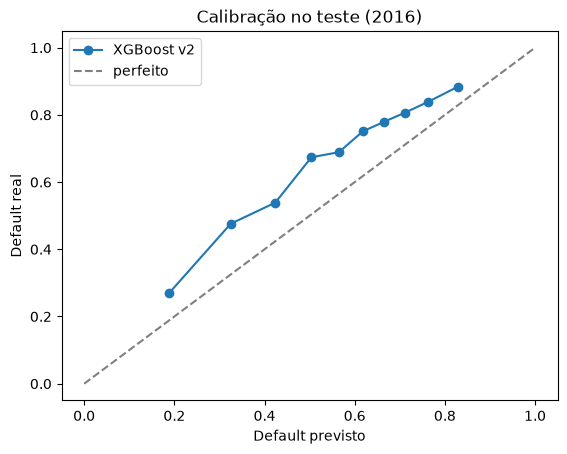

In [2]:
import matplotlib.pyplot as plt
from src.modelos.treino import comparar_com_bondora

print(comparar_com_bondora(teste, p))

c = calibracao_por_faixa(teste['default'], p)
plt.plot(c['prevista'], c['real'], 'o-', label='XGBoost v2')
plt.plot([0, 1], [0, 1], '--', color='gray', label='perfeito')
plt.xlabel('Default previsto'); plt.ylabel('Default real')
plt.title('Calibração no teste (2016)'); plt.legend(); plt.show()